<p style="text-align: center;"> Curso: Machine Learning</p>

<p style="text-align: center;"> Código Curso: 203008067 </p>

<p style="text-align: center;"> Grupo: 203008067_33 </p>

<p style="text-align: center;"> Fase 2 - Componente práctico - Algoritmos supervisados</p>

<p style="text-align: center;">  Presentado por: Luis Angel Quezada Aguirre</p>

<p style="text-align: center;">  Tutor(a): Jorge Luis Quintero</p>

<p style="text-align: center;"> UNIVERSIDAD NACIONAL ABIERTA Y A DISTANCIA - UNAD </p>


# Importación de liberías y datasets

In [1]:
# Manipulación y visualización de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pylab
import scipy.optimize as op

sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
pd.set_option('display.float_format', '{:.4f}'.format)

# Machine Learning (sklearn)
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression, Perceptron
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn import preprocessing
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier


print(" Todas las bibliotecas cargadas y configuradas.")


 Todas las bibliotecas cargadas y configuradas.


In [2]:
from sklearn.datasets import fetch_openml
dfr = fetch_openml(data_id=210, as_frame=True, parser="auto")  # data_id ya fija la version en OpenML
dfc = fetch_openml(data_id=1489, as_frame=True, parser="auto")



In [3]:
df1 = dfr.frame
df1.head()


,seeded,season,NC,SC,NWC,TE
0,S,AUTUMN,1.6500,1.8000,3.3300,1.6900
1,U,AUTUMN,1.0900,0.7900,1.5900,0.7400
2,S,WINTER,2.3900,0.3600,2.0600,0.8100
3,U,WINTER,2.9600,1.2700,4.0500,1.4400
4,S,WINTER,4.1600,2.1600,6.0000,2.4800


In [4]:
df2 = dfc.frame
df2.head()


,V1,V2,V3,V4,V5,Class
0,0.4899,-0.4515,-1.0480,-0.5987,-0.0204,1
1,-0.6413,0.1092,0.2921,-0.9168,0.2402,1
2,0.8706,-0.4599,0.5782,0.8066,0.8352,1
3,-0.6284,-0.3163,1.9343,-1.4271,-0.1366,1
4,-0.5964,0.0159,2.0432,-1.6884,-0.9481,1


# Ejercicio 1: Contextualización de los datasets.

Para el diseño de modelos de aprendizaje automático supervisado se utilizan conjuntos de datos abiertos provenientes de OpenML. Para el caso del diseño, comparación y evaluación de modelos de los diferentes modelos de regresión, se utiliza la base de datos ***Cloud (ID: 210)***, la cual contiene información sobre un experimento de siembra de nubes, que mide las precipitaciones de lluvia para ciertas zonas de Tasmania, entre los años de 1964 y 1971 (Rijn, 2014). El dataset contiene un tamaño de 108 entradas con 6 columnas, con variables númericas que miden la precipitación en pulgadas para ciertas zonas, en donde la variable dependiente *TE* representa el área este objetivo, y las variables *NC, SC y NWC* corresponden a las precipitaciones en las zonas de control norte, sur y noroeste, respectivamente; además, el dataset también contiene una varible binaria *seed* que da información sobre la siembra (S) o no (U) de las nubes, y la variable *season*, que señala la estación del año de la precipotación (Rijn, 2014).

Por otro lado, se utiliza el dataset ***Phoneme (ID: 1489)*** para el desarrollo de los modelos de clasificación. Este contiene información orientada a distinguir entre los sonidos nasales de los orales, por lo que esta (Class) será  la variable objetivo de los modelos; para tal fin, se utilizan datos de las primeras 5 harmónicas AHi/Ene, alojadas en las variables **V1, V2, V3, V4 Y V5** (Gomes Mantovani, 2015). En cuanto a tamaño, el dataset contiene 5404 entradas, distribuidas en 6 columnas/variables, en donde cinco son númerico-decimales y una es binaria. 

# Ejercicio 2: Análisis cuantitativo y cualitativo.

## Limpieza, preprocesamiento y Análisis exploratorio  de Datos (EDA) del dataset *Cloud (ID:210)*

### Limpieza y preprocesamiento

In [5]:
print("=== CARACTERIZACIÓN DEL DATASET CLOUD (ID:21O) ===")
print(df1.info())

print("\n=== tipo de datos (Dtypes) por columna ===")
print(df1.dtypes)

print("\n=== Valores faltantes por columna ===")
print(df1.isnull().sum())

print("\n=== Valores únicos en 'seeded' ===")
print(df1['seeded'].value_counts(dropna=False))

print("\n=== Valores únicos en 'season' ===")
print(df1['season'].value_counts(dropna=False))

print("\n=== Valores únicos en 'TE' ===")
print(df1['TE'].value_counts(dropna=False))


=== CARACTERIZACIÓN DEL DATASET CLOUD (ID:21O) ===
<class 'pandas.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   seeded  108 non-null    category
 1   season  108 non-null    category
 2   NC      108 non-null    float64 
 3   SC      108 non-null    float64 
 4   NWC     108 non-null    float64 
 5   TE      108 non-null    float64 
dtypes: category(2), float64(4)
memory usage: 3.8 KB
None

=== tipo de datos (Dtypes) por columna ===
seeded    category
season    category
NC         float64
SC         float64
NWC        float64
TE         float64
dtype: object

=== Valores faltantes por columna ===
seeded    0
season    0
NC        0
SC        0
NWC       0
TE        0
dtype: int64

=== Valores únicos en 'seeded' ===
seeded
S    54
U    54
Name: count, dtype: int64

=== Valores únicos en 'season' ===
season
SPRING    32
WINTER    28
AUTUMN    24
SUMMER    24
Name: count, dtype

In [6]:
# Función para detectar outliers por IQR
vars_num = ['TE', 'NC', 'SC', 'NWC']
def detect_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# Aplicar a cada variable
outliers_summary = {}
for var in vars_num:
    outliers, lb, ub = detect_outliers_iqr(df1, var)
    outliers_summary[var] = {
        'n_outliers': len(outliers),
        'lower_bound': lb,
        'upper_bound': ub,
        'outlier_rows': outliers.index.tolist()
    }
    print(f"\n--- {var} ---")
    print(f"Límites IQR: [{lb:.3f}, {ub:.3f}]")
    print(f"Número de outliers: {len(outliers)} ({100*len(outliers)/len(df1):.1f}%)")
    if len(outliers) <= 10:
        print("Índices de filas con outliers:", outliers.index.tolist())



--- TE ---
Límites IQR: [-1.231, 3.419]
Número de outliers: 5 (4.6%)
Índices de filas con outliers: [34, 67, 83, 86, 99]

--- NC ---
Límites IQR: [-2.174, 4.716]
Número de outliers: 3 (2.8%)
Índices de filas con outliers: [34, 83, 99]

--- SC ---
Límites IQR: [-1.156, 3.354]
Número de outliers: 3 (2.8%)
Índices de filas con outliers: [21, 83, 99]

--- NWC ---
Límites IQR: [-2.369, 6.301]
Número de outliers: 3 (2.8%)
Índices de filas con outliers: [67, 99, 100]


In [7]:
# PREPROCESAMIENTO CORREGIDO: MAPEO DE 'S'/'U'

df_prep = df1.copy()

# 1. Mapeo correcto de 'seeded': 'U' → 0 (sin siembra), 'S' → 1 (con siembra)
print("Valores únicos en 'seeded' antes del mapeo:", df_prep['seeded'].unique())
df_prep['seeded'] = df_prep['seeded'].map({'U': 0, 'S': 1})

# Verificar que no haya NaN tras el mapeo
if df_prep['seeded'].isnull().any():
    print("⚠️ Advertencia: aún hay valores no mapeados en 'seeded'")
else:
    print("✅ 'seeded' mapeado correctamente a 0/1")

# 2. One-hot encoding para 'season'
df_prep = pd.get_dummies(df_prep, columns=['season'], prefix='season', drop_first=True)

# 3. Verificar y eliminar solo filas con NaN reales (no causadas por mapeo erróneo)
print(f"\nFilas antes de limpieza: {len(df_prep)}")
df_prep = df_prep.dropna()
print(f"Filas después de limpieza: {len(df_prep)}")

# 4. Definir X e y
X = df_prep.drop(columns=['TE'])
y = df_prep['TE']

# 5. Asegurar tipo numérico
X = X.astype(np.float64)
y = y.astype(np.float64)

# 6. Dividir (solo si hay datos)
if len(df_prep) == 0:
    raise ValueError("El dataset está vacío después de la limpieza. Revisa los valores de 'seeded' y otras columnas.")
    
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"\n✅ Preprocesamiento exitoso. Datos listos: {X_train.shape[0]} ejemplos de entrenamiento.")


Valores únicos en 'seeded' antes del mapeo: ['S', 'U']
Categories (2, str): ['S', 'U']
✅ 'seeded' mapeado correctamente a 0/1

Filas antes de limpieza: 108
Filas después de limpieza: 108

✅ Preprocesamiento exitoso. Datos listos: 86 ejemplos de entrenamiento.


### Análisis Exploratorio de Datos (EDA) mediante visualización

In [8]:
print("Estadísticas descriptivas del dataset CLOUD (ID = 210)")
df1.describe()


Estadísticas descriptivas del dataset CLOUD (ID = 210)


,NC,SC,NWC,TE
count,108.0000,108.0000,108.0000,108.0000
mean,1.5064,1.2021,2.1929,1.2326
std,1.4317,0.8918,1.6329,1.0772
min,0.0000,0.0200,0.0400,0.0000
25%,0.4100,0.5350,0.8825,0.5125
50%,1.2850,0.9950,1.9150,0.9100
75%,2.1325,1.6625,3.0500,1.6750
max,9.4200,4.0200,7.8400,6.0000


**1)** Diagrama de dispersión

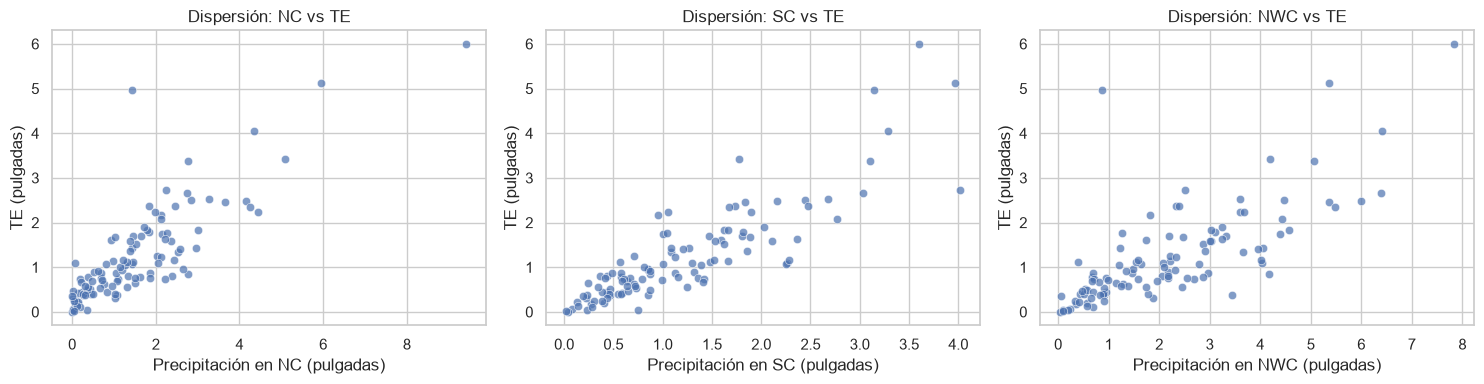

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
plt.figure(figsize=(15, 4))

for i, var in enumerate(['NC', 'SC', 'NWC'], 1):
    plt.subplot(1, 3, i)
    sns.scatterplot(data=df1, x=var, y='TE', alpha=0.7)
    plt.title(f'Dispersión: {var} vs TE')
    plt.xlabel(f'Precipitación en {var} (pulgadas)')
    plt.ylabel('TE (pulgadas)')

plt.tight_layout()
plt.show()


**2)** Diagramas de barras e histogramas

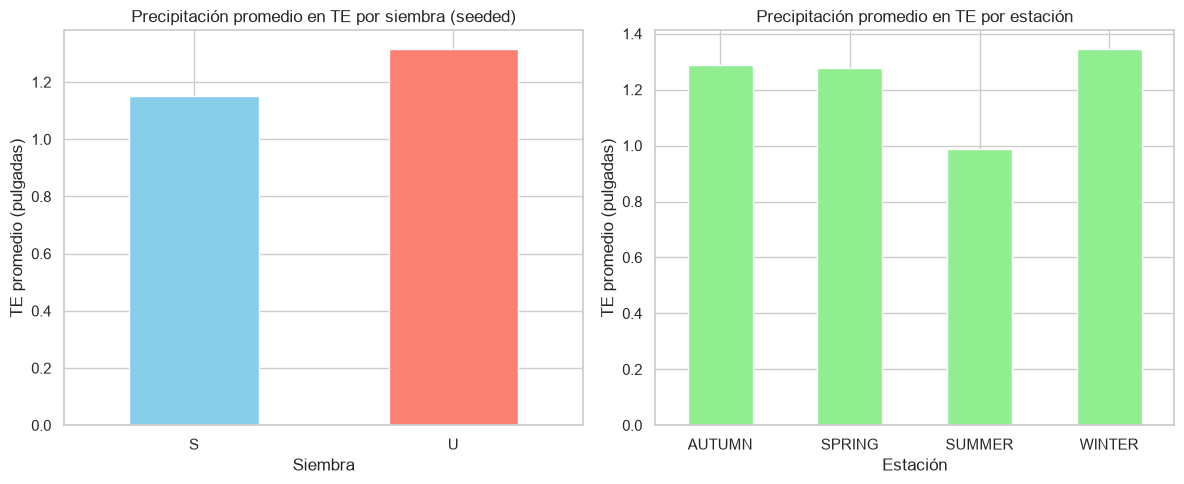

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Por 'seeded'
df1.groupby('seeded')['TE'].mean().plot(kind='bar', ax=axes[0], color=['skyblue', 'salmon'])
axes[0].set_title('Precipitación promedio en TE por siembra (seeded)')
axes[0].set_xlabel('Siembra')
axes[0].set_ylabel('TE promedio (pulgadas)')
axes[0].tick_params(axis='x', rotation=0)

# Por 'season'
df1.groupby('season')['TE'].mean().plot(kind='bar', ax=axes[1], color='lightgreen')
axes[1].set_title('Precipitación promedio en TE por estación')
axes[1].set_xlabel('Estación')
axes[1].set_ylabel('TE promedio (pulgadas)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


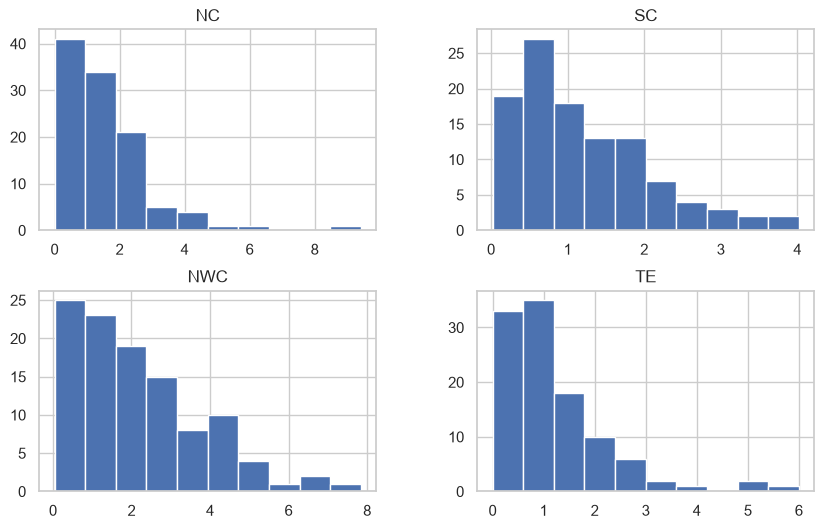

In [11]:
viz = df1[['NC','SC','NWC','TE']]
viz.hist()
plt.show()


**3)** Boxplots

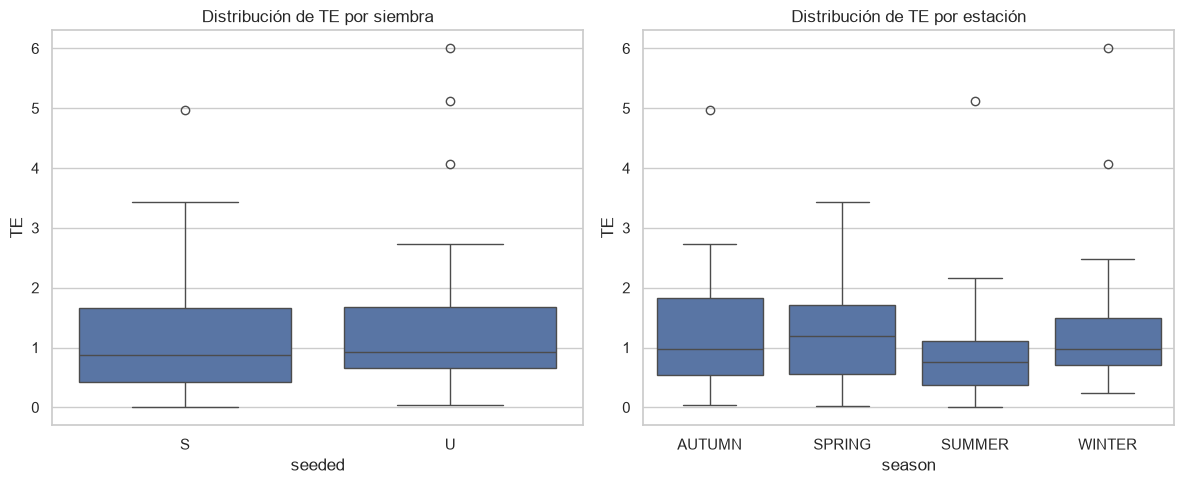

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df1, x='seeded', y='TE', ax=axes[0])
axes[0].set_title('Distribución de TE por siembra')

sns.boxplot(data=df1, x='season', y='TE', ax=axes[1])
axes[1].set_title('Distribución de TE por estación')

plt.tight_layout()
plt.show()


**4)** Tabla de contingencia

In [13]:
# Tabla de contingencia: seeded × season
contingency_table = pd.crosstab(df1['seeded'], df1['season'], margins=True)
print("=== Tabla de contingencia: seeded vs season ===")
display(contingency_table)

# Opcional: con porcentajes
contingency_pct = pd.crosstab(df1['seeded'], df1['season'], normalize='all') * 100
print("\n=== Porcentajes (%) ===")
display(contingency_pct.round(2))


=== Tabla de contingencia: seeded vs season ===


season,AUTUMN,SPRING,SUMMER,WINTER,All
seeded,,,,,
S,12,16,12,14,54
U,12,16,12,14,54
All,24,32,24,28,108



=== Porcentajes (%) ===


season,AUTUMN,SPRING,SUMMER,WINTER
seeded,,,,
S,11.1100,14.8100,11.1100,12.9600
U,11.1100,14.8100,11.1100,12.9600


**5)** Matriz de correlaciones (Heatmap)

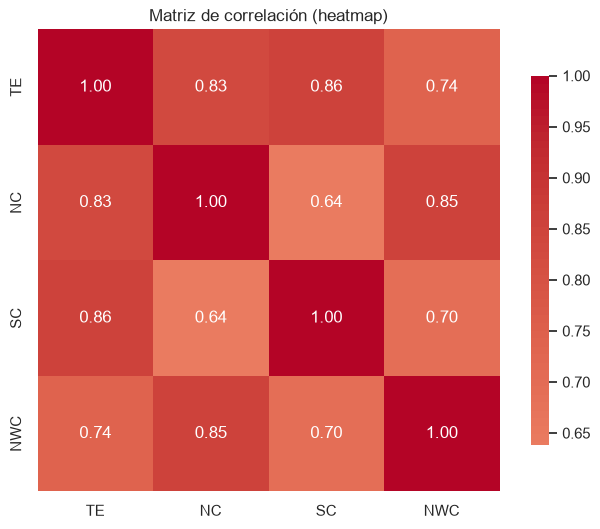

In [14]:
# Seleccionar solo variables numéricas
numeric_cols = ['TE', 'NC', 'SC', 'NWC']

# Calcular matriz de correlación
corr_matrix = df1[numeric_cols].corr()

# Visualizar con heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, 
            annot=True, 
            cmap='coolwarm', 
            center=0, 
            square=True,
            fmt=".2f",
            cbar_kws={"shrink": .8})
plt.title('Matriz de correlación (heatmap)')
plt.show()


### Hallazgos preliminares

La visualización general de las características el dataset permite observar que el dataset se encuentra preprocesado y limpio. No contiene valores nulos, los tipos de dato de cada columna están en orden, y el procentaje de outliers tanto en la variable objetivo (TE) como en las variables independientes es bajo, siendo de solo 4.6% para la variable (TE) y de 2.8% para el resto de variables. Sin embargo, fue necesaria la codificación de las variables categóricas como 'season' y 'seed' para su uso dentro del modelo, utilizando procesos de binarización y one-hot encoding.

Por otro lado, el análisis exploratorio dió indicios tanto para la elección tanto de los modelos de regresión, así como de la variable dependiente e independientes. La distribución de los datos en el diagrama de dispersión muestran una tendencia lineal, y la matriz de correlación (heatmap) nos expone que la correlación de pearson entre las variable TE y el resto de variables es alta; por ende, se establece que se utilizarán más de una variable independiente para observar su relación con las precipitaciones de la zona este (TE). 

Se debe señalar que el modelo presenta un grado significativo de multicolinealidad. Esta se produce cuando más de dos variables independientes de una ecuación de regresión lineal están correlacionadas, lo cual puede afectar negativamente la capacidad del modelo para predecir datos no observador y generar sobre ajuste (Kavlakoglu y Murel, s.f). 

No obstante, lo anterior no es grave. Debe tenerse en cuenta la naturaleza de los datos, en donde las variables predictoras (`NC`, `SC`, `NWC`) representan mediciones de precipitación en zonas geográficamente cercanas, lo que naturalmente genera correlaciones positivas; por otro lado, no se hayan correlaciones perfectas, y como se verá más adelante, la multicolinealidad no afecta la capacidad predictiva de los modelos, ya que el R² de tres de los cuatro modelos da más de 0.9

# Ejercicio 3: Modelos de regresión.

**FUNCIÓN PARA LA EVALUACIÓN CONJUNTA DE MODELOS**

In [15]:
def evaluar_modelo(modelo, X_train, X_test, y_train, y_test, nombre):
    # Entrenar
    modelo.fit(X_train, y_train)
    
    # Predecir
    y_train_pred = modelo.predict(X_train)
    y_test_pred = modelo.predict(X_test)
    
    # Métricas en prueba (usaremos solo test para comparar)
    mse  = mean_squared_error(y_test, y_test_pred)
    mae  = mean_absolute_error(y_test, y_test_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_test, y_test_pred)
    
    return {
        'Modelo': nombre,
        'MSE': mse,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    }


**DIVISÓN DE LOS DATOS**

In [16]:
# Definir variables
X = df_prep.drop(columns=['TE'])
y = df_prep['TE']

# División fija (para comparabilidad)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)


## 1. Regresión lineal.

In [17]:
modelo_lr = LinearRegression()
resultados_lr = evaluar_modelo(modelo_lr, X_train, X_test, y_train, y_test, "Regresión Lineal")

# Mostrar coeficientes
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': modelo_lr.fit(X_train, y_train).coef_
})
coef_df.loc['Intercepto'] = ['Intercepto', modelo_lr.intercept_]
print("Coeficientes del modelo lineal:")
display(coef_df.sort_values('Coeficiente', key=abs, ascending=False))


Coeficientes del modelo lineal:


,Variable,Coeficiente
2,SC,0.6952
1,NC,0.4990
6,season_WINTER,-0.2894
3,NWC,-0.1478
5,season_SUMMER,-0.1154
4,season_SPRING,-0.0990
0,seeded,0.0658
Intercepto,Intercepto,0.0439


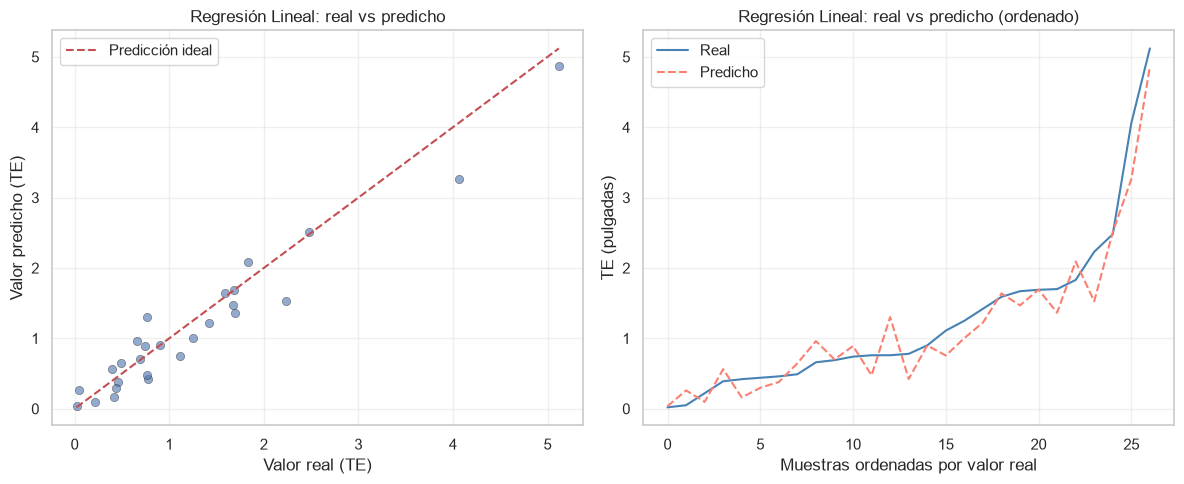

In [18]:
# Gráfica del modelo: Regresión Lineal (valores reales vs predichos)
y_pred = modelo_lr.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1) Dispersión real vs predicho + línea ideal
axes[0].scatter(y_test, y_pred, alpha=0.6, edgecolor='k', linewidth=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', lw=1.5, label='Predicción ideal')
axes[0].set_xlabel('Valor real (TE)')
axes[0].set_ylabel('Valor predicho (TE)')
axes[0].set_title('Regresión Lineal: real vs predicho')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2) Líneas ordenadas por valor real
orden = np.argsort(y_test.values)
axes[1].plot(np.arange(len(y_test)), y_test.values[orden], label='Real', color='steelblue')
axes[1].plot(np.arange(len(y_test)), y_pred[orden], label='Predicho', color='salmon', linestyle='--')
axes[1].set_xlabel('Muestras ordenadas por valor real')
axes[1].set_ylabel('TE (pulgadas)')
axes[1].set_title('Regresión Lineal: real vs predicho (ordenado)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 2. Ridge.

In [19]:
modelo_ridge = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0, random_state=42))
])

resultados_ridge = evaluar_modelo(
    modelo_ridge, X_train, X_test, y_train, y_test, "Regresión Ridge"
)


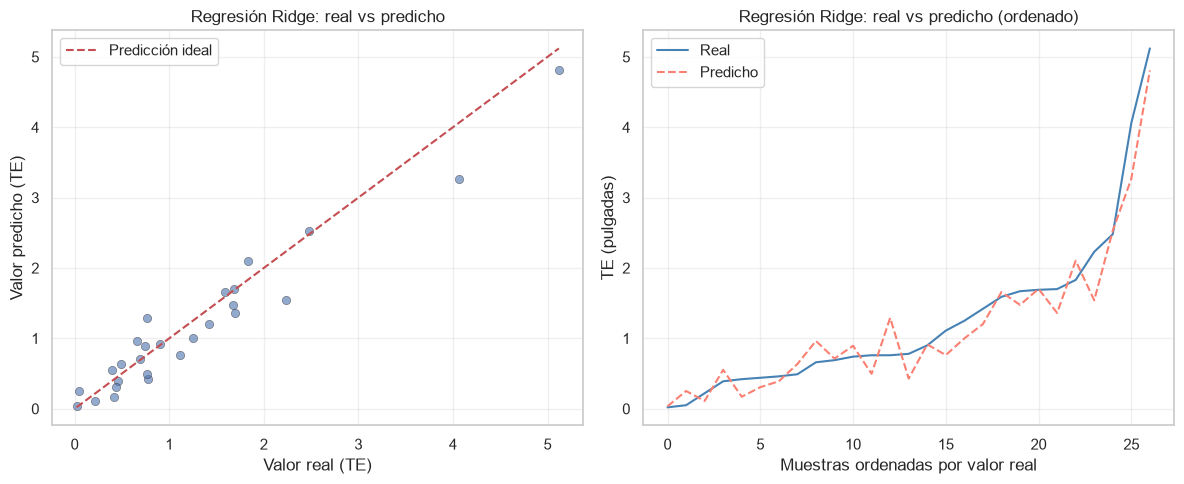

In [20]:
# Gráfica del modelo: Regresión Ridge (valores reales vs predichos)
y_pred = modelo_ridge.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1) Dispersión real vs predicho + línea ideal
axes[0].scatter(y_test, y_pred, alpha=0.6, edgecolor='k', linewidth=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', lw=1.5, label='Predicción ideal')
axes[0].set_xlabel('Valor real (TE)')
axes[0].set_ylabel('Valor predicho (TE)')
axes[0].set_title('Regresión Ridge: real vs predicho')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2) Líneas ordenadas por valor real
orden = np.argsort(y_test.values)
axes[1].plot(np.arange(len(y_test)), y_test.values[orden], label='Real', color='steelblue')
axes[1].plot(np.arange(len(y_test)), y_pred[orden], label='Predicho', color='salmon', linestyle='--')
axes[1].set_xlabel('Muestras ordenadas por valor real')
axes[1].set_ylabel('TE (pulgadas)')
axes[1].set_title('Regresión Ridge: real vs predicho (ordenado)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Lasso.

In [21]:
modelo_lasso = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.1, random_state=42, max_iter=10000))
])

resultados_lasso = evaluar_modelo(
    modelo_lasso, X_train, X_test, y_train, y_test, "Regresión Lasso"
)

# Opcional: mostrar coeficientes (solo para análisis)
modelo_lasso.fit(X_train, y_train)
coef_lasso = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente_Lasso': modelo_lasso.named_steps['lasso'].coef_
})
print("\nCoeficientes Lasso (valores cercanos a 0 indican variables descartadas):")
display(coef_lasso.sort_values('Coeficiente_Lasso', key=abs, ascending=False))



Coeficientes Lasso (valores cercanos a 0 indican variables descartadas):


,Variable,Coeficiente_Lasso
2,SC,0.5049
1,NC,0.4532
0,seeded,0.0000
3,NWC,0.0000
4,season_SPRING,0.0000
5,season_SUMMER,0.0000
6,season_WINTER,-0.0000


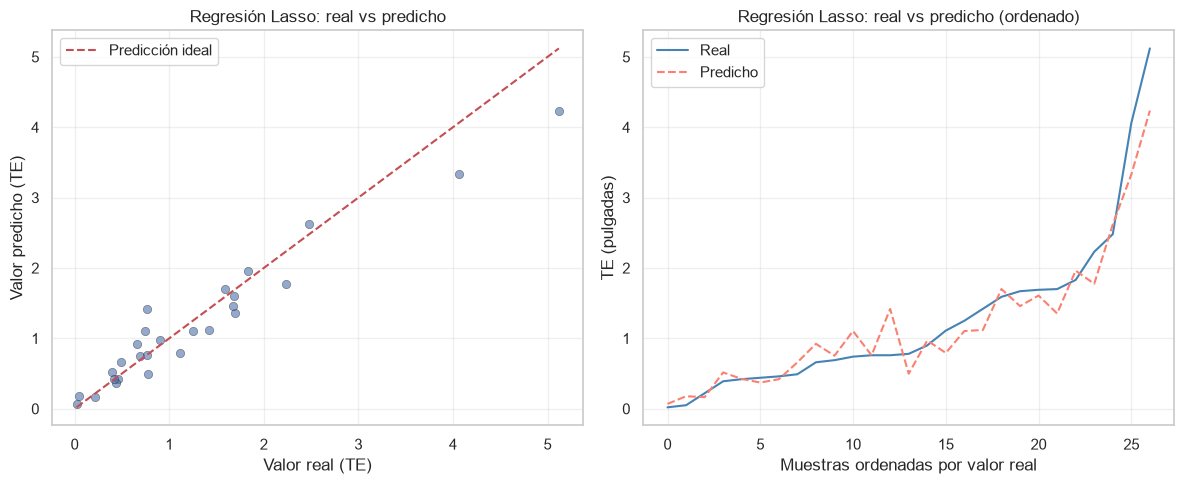

In [22]:
# Gráfica del modelo: Regresión Lasso (valores reales vs predichos)
y_pred = modelo_lasso.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1) Dispersión real vs predicho + línea ideal
axes[0].scatter(y_test, y_pred, alpha=0.6, edgecolor='k', linewidth=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', lw=1.5, label='Predicción ideal')
axes[0].set_xlabel('Valor real (TE)')
axes[0].set_ylabel('Valor predicho (TE)')
axes[0].set_title('Regresión Lasso: real vs predicho')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2) Líneas ordenadas por valor real
orden = np.argsort(y_test.values)
axes[1].plot(np.arange(len(y_test)), y_test.values[orden], label='Real', color='steelblue')
axes[1].plot(np.arange(len(y_test)), y_pred[orden], label='Predicho', color='salmon', linestyle='--')
axes[1].set_xlabel('Muestras ordenadas por valor real')
axes[1].set_ylabel('TE (pulgadas)')
axes[1].set_title('Regresión Lasso: real vs predicho (ordenado)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 4. Árbol de decisión.

In [23]:
modelo_rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

resultados_rf = evaluar_modelo(
    modelo_rf, X_train, X_test, y_train, y_test, "Random Forest"
)

# Opcional: importancia de variables
modelo_rf.fit(X_train, y_train)
importancia_rf = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': modelo_rf.feature_importances_
}).sort_values('Importancia', ascending=False)

print("\nImportancia de variables (Random Forest):")
display(importancia_rf)



Importancia de variables (Random Forest):


,Variable,Importancia
2,SC,0.5733
1,NC,0.3273
3,NWC,0.0788
6,season_WINTER,0.0094
4,season_SPRING,0.0065
0,seeded,0.0038
5,season_SUMMER,0.0010


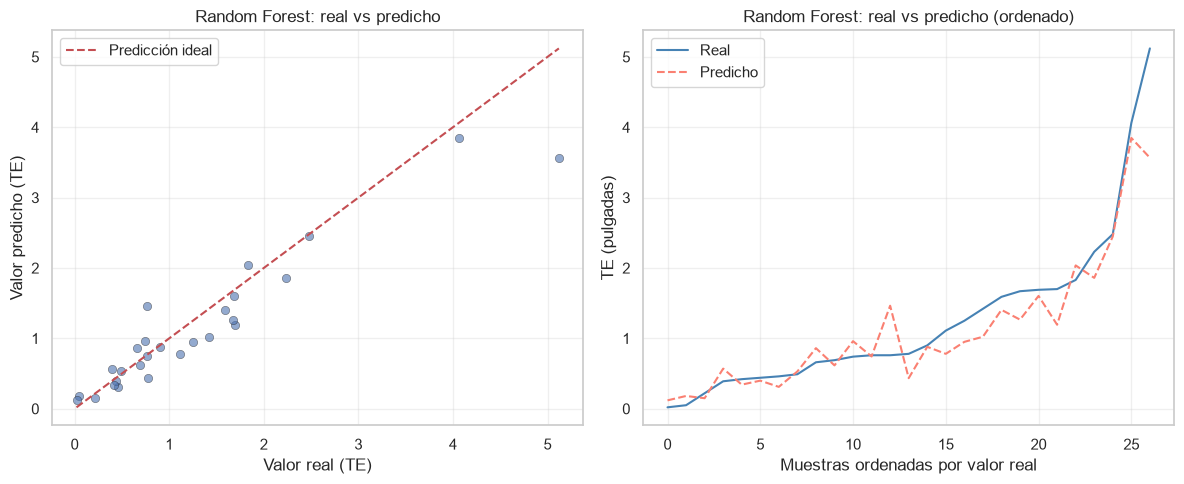

In [24]:
# Gráfica del modelo: Random Forest (valores reales vs predichos)
y_pred = modelo_rf.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1) Dispersión real vs predicho + línea ideal
axes[0].scatter(y_test, y_pred, alpha=0.6, edgecolor='k', linewidth=0.4)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', lw=1.5, label='Predicción ideal')
axes[0].set_xlabel('Valor real (TE)')
axes[0].set_ylabel('Valor predicho (TE)')
axes[0].set_title('Random Forest: real vs predicho')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2) Líneas ordenadas por valor real
orden = np.argsort(y_test.values)
axes[1].plot(np.arange(len(y_test)), y_test.values[orden], label='Real', color='steelblue')
axes[1].plot(np.arange(len(y_test)), y_pred[orden], label='Predicho', color='salmon', linestyle='--')
axes[1].set_xlabel('Muestras ordenadas por valor real')
axes[1].set_ylabel('TE (pulgadas)')
axes[1].set_title('Random Forest: real vs predicho (ordenado)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Evaluación comparada de modelos

In [25]:
todos_resultados = [
    resultados_lr,
    resultados_ridge,
    resultados_lasso,
    resultados_rf
]

# Crear DataFrame
df_comparacion = pd.DataFrame(todos_resultados).round(4)
df_comparacion = df_comparacion.set_index('Modelo')

# Mostrar tabla
display(df_comparacion)

# Identificar mejor modelo por métrica
print("\n Mejor modelo por métrica:")
print(f"• Menor MSE  : {df_comparacion['MSE'].idxmin()}")
print(f"• Menor MAE  : {df_comparacion['MAE'].idxmin()}")
print(f"• Menor RMSE : {df_comparacion['RMSE'].idxmin()}")
print(f"• Mayor R²   : {df_comparacion['R2'].idxmax()}")


,MSE,MAE,RMSE,R2
Modelo,,,,
Regresión Lineal,0.0916,0.2312,0.3026,0.9303
Regresión Ridge,0.0904,0.2324,0.3007,0.9312
Regresión Lasso,0.1018,0.2294,0.3191,0.9225
Random Forest,0.1579,0.2576,0.3974,0.8798



 Mejor modelo por métrica:
• Menor MSE  : Regresión Ridge
• Menor MAE  : Regresión Lasso
• Menor RMSE : Regresión Ridge
• Mayor R²   : Regresión Ridge


Los resultados de las métricas nos permiten observar el desempeño de cada uno de los modelos. Es de destacar que la regresión ridge obtuvo el mejor desempeño en 3 de las 4 métricas; sin embargo, la más importante para este caso es, sin duda, su resultado de R², el cual indica la proporción de la varianza en los datos que es explicada por el modelo (Accio, s.f), en donde la regresión de ridge obvtuvo el mejor puntaje. Sin embargo, su diferencia con las regresiones lineal y lasso no es abismal, lo que indica que estos también representan modelos de buen desempeño.

Basado en lo anterior, se escoge a la regresión de ridge como el mejor modelo para este caso.

**FUNCIÓN PARA LA EVALUACIÓN CONJUNTA DEL MODELO**

# Ejercicio 5: Feedback.

In [26]:
# NOTA: coloca tu captura en assets/fase2-evidencia.png (ruta relativa portable).
from pathlib import Path
from IPython.display import Image, display
ruta_imagen = "assets/fase2-evidencia.png"  # ANTES: ruta absoluta OneDrive (no portable)
p_img = Path(ruta_imagen)
# Buscar tambien desde la raiz del repo (notebook vive en notebooks/04-proyecto-unad/)
for cand in [p_img, Path("../../assets/fase2-evidencia.png"), Path.cwd() / ruta_imagen]:
    if cand.exists():
        p_img = cand
        break
if p_img.exists():
    display(Image(filename=str(p_img), width=800))
else:
    print(f"[info] Imagen no encontrada en {ruta_imagen}: coloca tu captura ahi o ignora esta celda.")


[info] Imagen no encontrada en assets/fase2-evidencia.png: coloca tu captura ahi o ignora esta celda.


# Referencias

Accio (s.f). Qué es el r2 en una linea de tendencia. En *Accio.* https://www.accio.com/business/es/que-es-el-r2-en-una-linea-de-tendencia

Gomes Mantovani, R. (2015). Phoneme. *En OpenML.* https://www.openml.org/search?type=data&status=active&id=1489

Kavlakoglu, E., Murel, J. (s.f). ¿Qué es la multicolinealidad?. En *IBM*. https://www.ibm.com/es-es/think/topics/multicollinearity

Rijn, J. (2014). Cloud. En *OpenML*. https://www.openml.org/search?type=data&status=active&id=210

Vina, A. (2025). Exactitud, precisión y exhaustividad en el aprendizaje automático. En *Ultralytics*. https://www.ultralytics.com/es/blog/accuracy-precision-recall
